# 原始import和质谱数据读数

In [1]:
from IPython.core.interactiveshell import InteractiveShell
InteractiveShell.ast_node_interactivity = "all"
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pywt
from matplotlib.font_manager import FontProperties
import pickle
import math
import scipy
import scipy.signal
import vector
import json
import zipfile
import os

%matplotlib inline 
#np.set_printoptions(threshold=np.inf)

# pd.set_option('display.max_columns', None) #原来中间会有部分列的显示被省略

def filters_main(spec,use_new=2):
    #comprehensive filters that handle the filter process
    #set use_new to 0 if use movemean 20pt, use_new to 1 if fir

    ## baseline 1
    # old mov_mean does not use
    # 输入一个list
    spec=np.array(spec)#转化成numpy形式
    if use_new == 1 or use_new == 2:
        baseline_1 = spec
    else:
        baseline_1 = spec

    ## filter
    if use_new == 2:
        filtered = filter_gaus(baseline_1)
    elif use_new == 0:
        # default 21pt filter
        filtered = filter_mov(baseline_1)

    ## baseline correction2
    if use_new == 1 or use_new == 2:
        out = filtered - matlab_percentile(filtered, 10)
        out[out < 0] = 0
    elif use_new == 0:
        filtered[filtered < 0] = 0
        out = filtered - filtered.min()

    out = out.tolist()
    #print(type(out)) = list
    #print(out) = []
    return(out)

def filter_gaus(input_spec,cycle=1):

    window = 100
    alpha = 6
    std = (window - 1) / (2 * alpha)
    b = scipy.signal.windows.gaussian(window, std, sym=True)
    b = b / sum(b)
    output_spec = np.convolve(input_spec, b,'same')
    for i in range(2, cycle + 1):
        output_spec = np.convolve(input_spec, b,'same')
    return(output_spec)



def filter_mov(input_spec, window=21, cycle=1):
    # input_spec is a 1d array
    # window is the width of the move mean
    # cycle is the repetive number
    use_old = 1
    if use_old != 0:
        MEAN_SIZE = window - 1
        for k in range(1,cycle+1):
            half = MEAN_SIZE/ 2
            npt=MEAN_SIZE+1
            lentmp1=len(input_spec)
            if half < 1:
                tmp =input_spec
            else:
                tmp=[]
                for i in range(0,lentmp1):
                    if i>=0 and i<=half-1 or i>=lentmp1-half-1 and  i<=lentmp1-1:
                        mean_value=math.floor(np.mean(input_spec[0:10]))
                        tmp.append((input_spec[i]-mean_value)/npt+mean_value)
                    else:
                        tmp.append(math.floor(np.mean(input_spec[i-10-1:i+10])))

                tmp = np.array(tmp)
            tmp=np.transpose(tmp)
            output_spec=tmp
    else:

        b = (1 / window) * np.ones(window)
        output_spec=np.convolve(input_spec,b,'same')
        for i in range(2,cycle+1):
            output_spec=np.convolve(input_spec,b,'same')

    return(output_spec)




def matlab_percentile(x, p):
    p = np.asarray(p, dtype=float)
    n = len(x)
    p = (p-50)*n/(n-1) + 50
    p = np.clip(p, 0, 100)
    baseline=np.percentile(x, p)
    return(baseline)

def get_spec_params(data,is_neg=0):
# is_neg=0时：正模式，输入一个参数正模式
    if is_neg: #负模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters_neg']['spec_parameters']['calib_mass_start']['value']
    else: #正模式
        mass_calib_c0 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c0']['value']
        mass_calib_c1 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c1']['value']
        mass_calib_c2 = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['mass_calib_c2']['value']
        calib_mass_start = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['spec_parameters']['calib_mass_start']['value']

    return(mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start)

def Method1_get_filelist(path): #path = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/20PPM/'  # (一个文件夹)
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if 'mrz' in file:
                file_list.append(os.path.join('%s%s' % (root, file)))
  # file_list 是一个list
    return(file_list)
def load_mrz(name):  #filepath = 'W:/study/PHD1/检测器tutorial/10.30数据/different_ppm_samePara/500PPB/1.mrz' , type=mrz
    zfile = zipfile.ZipFile(name)   #zfile.namelist()={'arbitrary_2021_10_30_18_07_11_227.json'}
    if len(zfile.namelist()) ==1:
        for filenames in zfile.namelist():
            zfile.extract(filenames, path=os.getcwd())
            file = os.getcwd() + '/' + filenames
            with open(file, "r", encoding='utf-8') as fp:
                data = json.load(fp)
            if os.path.exists(file):  # 如果文件存在
                os.remove(file)
        return(data)
    
def process_mrz_data(data,use_new_filter=2):
    n=0
    while n<=(len(data['analysis']['scan_list'])-1):
        pt_per_th = data['analysis']['parameters_files']['static_parameters']['static_parameters']['pt_per_th']
        scan_speed = data['analysis']['parameters_files']['instrument_parameters']['instrument_parameters']['calib_parameters']['scan_speed']['value']
        if data['analysis']['scan_list'][n]['method_parameters']['polarity'] == "NEG":
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data, 1)
        else:
            [mass_calib_c0, mass_calib_c1, mass_calib_c2, calib_mass_start] = get_spec_params(data)

        if type(data['analysis']['scan_list'][n]['raw_data'][0])== "dict":
            print('data是字典结构，请重新调试程序')
            #data['analysis']['scan_list'][n]['filtered']={}
            data['analysis']['scan_list'][n]['mz'] = {}
            for len_data in range(0,len(data['analysis']['scan_list'][n]['data'])):
                if len(data['analysis']['scan_list'][n]['data'][0])==1:
                    if data['analysis']['scan_list'][n].__contains__('raw_counting_data') and data['analysis']['scan_list'][n].__contains__('raw_analog_data'):
                        # filtered the analog data
                        data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_analog_data'][0],use_new_filter)
                        data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]


                if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                    x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

                else:
                    x0=[i for i in range(0,len_data)]
                    data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                    data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]


                # prepare the temp
                if data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c0') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c1') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('mass_temp_comp_c2') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('current_temperature') and data['analysis']['scan_list'][n]['spec_parameters'].__contains__('calib_temperature'):
                    if float(data['analysis']['config']['DataProcessing']['mass_temp_comp_enabled']) == 1:
                        t_c0 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c0']
                        t_c1 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c1']
                        t_c2 = data['analysis']['scan_list'][n]['spec_parameters']['mass_temp_comp_c2']
                        dt = data['analysis']['scan_list'][n]['spec_parameters']['current_temperature'] - data['analysis']['scan_list'][n]['spec_parameters']['calib_temperature']

                        data['analysis']['scan_list'][n]['mz'] = temp_correction(data['analysis']['scan_list'][n]['mz'],t_c0, t_c1, t_c2, dt)
                        data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]

        else:
            data['analysis']['scan_list'][n]['analog_filtered'] = filters_main(data['analysis']['scan_list'][n]['raw_data'], 2)
            data['analysis']['scan_list'][n]['analog_filtered'] = [data['analysis']['scan_list'][n]['analog_filtered']]
            #prepare the mz
            len_data=len(data['analysis']['scan_list'][n]['raw_data'])
            if data['analysis']['scan_list'][n]['method_parameters'].__contains__('scan_mass_start') and calib_mass_start != data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']:
                x0 = [i+pt_per_th * (data['analysis']['scan_list'][n]['method_parameters']['scan_mass_start']-calib_mass_start) for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
            else:
                x0=[i for i in range(0,len_data)]
                data['analysis']['scan_list'][n]['mz'] = np.polyval([mass_calib_c2, mass_calib_c1, mass_calib_c0], x0).tolist()
                data['analysis']['scan_list'][n]['mz'] = [data['analysis']['scan_list'][n]['mz']]
        n=n+1
    return(data)
                                                        
                                                          
def baseline_delete_method2(raw_data_list):   #所有的数据 按照平均值的正负3倍std,速度很慢
    spec = np.array(raw_data_list)
    baseline = spec
    i = 0
    mean_base=[]
    std_base=[]
    while i < 3 :
        mean_base.append(np.mean(baseline))
        std_base.append(np.std(baseline))
        baseline = spec[np.where(spec<(mean_base[i] + 3*std_base[i]))]
        i = i+1
    if np.size(spec,0)==1:
        filterd_data = spec - np.mean(baseline) # [[class 'numpy.ndarray']]
    else:
        print('请检查raw_data维数')
    return (filterd_data) ## <class 'numpy.ndarray'>

# 质谱生成cwt

In [2]:
# 获得一个文件夹里所有的文件名称，并生成spectrogram （文件夹处理）
import os

def Method1_get_filelist(path, file_extension='.mrz',file_start='NMS1-1'):
    file_list = []
    for root, dirs, files in os.walk(path):
        for file in files:
            if file.startswith(file_start) and file.endswith(file_extension):  # 检查文件名前缀和后缀
                file_list.append(os.path.join(root, file))
    return file_list
# Method1_get_filelist('D:/DATA/ZHY/cwt图像处理/2hg/')
# eg: Method1_get_filelist('E:/神经胶质瘤/HS_data_new/1/')

import numpy as np
from scipy.linalg import expm, logm
import matplotlib.pyplot as plt

def process_files(folder_path):
    file_list = Method1_get_filelist(folder_path)
    spectrograms = []

# 创建一个用于存放图像的新文件夹
    output_folder = os.path.join(folder_path, 'SpectrogramsPlot')
    if not os.path.exists(output_folder):
        os.makedirs(output_folder)

    for name in file_list:
        data = load_mrz(name)
        data = process_mrz_data(data, use_new_filter=2)

        y_int = data['analysis']['scan_list'][0]['analog_filtered'][0]
        x_mz = data['analysis']['scan_list'][0]['mz'][0]

        plt.plot(x_mz, y_int)
        # 保存图像到新文件夹
        plt.savefig(os.path.join(output_folder, f'{os.path.basename(name)}_plot.svg'), format='svg')
        plt.close()  # 防止显示图像
        spectrogram = np.array([x_mz, y_int])
        spectrograms.append(spectrogram)
        
    return spectrograms

In [ ]:
import numpy as np
import pywt
import matplotlib.pyplot as plt
from skimage.transform import resize

def generate_spectrogram(mass_spec_data, 
                         signal_length=1200, 
                         fs=144, 
                         voices_per_octave=10, 
                         wavelet_params=(3,60), 
                         output_size=(224,224)):
    """
    将质谱数据（一维信号）转换为 CWT 尺度图，并最终生成 224x224 的 RGB 图像。

    参数：
    - mass_spec_data: 一维 numpy 数组，包含质谱数据。
    - signal_length: 处理使用的信号长度，如原文指定为1200。
    - fs: 采样频率 (Frequency)。如文中给出为144。
    - voices_per_octave: 每个倍频程的尺度数目，用于确定尺度分布。文中给出为10。
    - wavelet_params: 小波参数 (如 [3,60])，用于构造 cmor 小波。这里将其映射为 'cmor3-60'。
    - output_size: 输出图像大小，如 (224,224)。

    返回：
    - rgb_image: 生成的 RGB 图像 (numpy 数组)，大小为 (224, 224, 3)。
    """

    # 确保数据为列向量
    mass_spec_data = np.asarray(mass_spec_data).flatten()

    # 如果数据长度大于1200，则下采样或截取
    if len(mass_spec_data) != signal_length:
        # 简单下采样到指定长度
        factor = len(mass_spec_data) / signal_length
        # 使用因子下采样(向下取整以避免溢出)
        factor = int(np.floor(factor))
        if factor < 1:
            # 如果原数据小于signal_length，则可以做padding或者直接不下采样
            # 这里简单截取前面部分（实际可根据需要改进）
            mass_spec_data = mass_spec_data[:signal_length]
        else:
            mass_spec_data = mass_spec_data[::factor]
            # 若下采样后长度仍不满足signal_length，则再截取或补齐
            mass_spec_data = mass_spec_data[:signal_length]

    # 确保最终长度为1200
    mass_spec_data = mass_spec_data[:signal_length]

    # 时间步长
    dt = 1.0 / fs

    # 根据给定参数构造小波名称
    # 原文是解析莫尔斯小波 (Morlet)参数 [3,60]，这里尝试使用 cmor 小波替代
    # PyWavelets中cmorB-C形式，B为带宽参数，C为中心频率参数，这里直接使用 cmor3-60
    wavelet = f'cmor{wavelet_params[0]}-{wavelet_params[1]}'

    # 构造尺度数组（scales）
    # voices_per_octave = 10 表示每个倍频程10个尺度
    # 假设频率范围：最高频率 ~ Nyquist = fs/2 = 72 Hz，最低频率设为 1 Hz
    # 总共约 log2(72) ≈ 6倍频程，6 * 10 = 60左右的尺度
    lowest_freq = 1.0
    highest_freq = fs / 2.0  # Nyquist频率
    num_scales = int(round(np.log2(highest_freq/lowest_freq) * voices_per_octave))

    # 在对数频率轴上均匀取点
    freqs = np.logspace(np.log10(highest_freq), np.log10(lowest_freq), num=num_scales)
    # scale = fs / freq (对于cmor小波，频率与尺度成反比)
    scales = fs / freqs

    # 执行CWT
    coefficients, frequencies = pywt.cwt(mass_spec_data, scales, wavelet, sampling_period=dt)

    # 获取尺度图(取绝对值)
    scale_map = np.abs(coefficients)

    # 归一化到[0,1]
    scale_map_norm = (scale_map - scale_map.min()) / (scale_map.max() - scale_map.min())

    # 调整尺度图大小到224x224
    scale_map_resized = resize(scale_map_norm, output_size, mode='constant')

    # 转换为RGB图像（简单复制三份通道得到灰度RGB）
    rgb_image = np.stack([scale_map_resized]*3, axis=-1)

    return rgb_image

In [3]:
import numpy as np
from scipy import signal
import matplotlib.pyplot as plt

def generate_spectrogram(spectrogram, scales):
    """
    根据给定的质谱数据和尺度范围生成时频图。
    """
    signal_strength = spectrogram[1]
    wavelet = signal.ricker
    cwt_matrix = signal.cwt(signal_strength, wavelet, scales)
    return np.abs(cwt_matrix)
    
def calculate_entropy(cwt_matrix):
    probability_matrix = cwt_matrix / cwt_matrix.sum()
    entropy = -np.sum(probability_matrix * np.log2(probability_matrix + 1e-12))
    return entropy

def generate_scale_options(num_scales):
    """
    生成不同数量尺度点的尺度数组。
    每个数组的范围是从1到100，但具有不同的间隔。
    """
    scale_options = []
    for n in num_scales:
        scales = np.linspace(1, 100, n, dtype=int)
        scale_options.append(scales)
    return scale_options
    
def calculate_energy_distribution(cwt_matrix):
    # 计算能量分布
    energy_distribution = [np.sum(np.square(row)) for row in cwt_matrix]
    return energy_distribution

def uniformity_score(energy_distributions):
    # 计算能量分布的标准偏差，以评估均匀性
    return np.std(energy_distributions)

def calculate_entropy_with_penalty(cwt_matrix):
    """
    计算带惩罚的信息熵。
    """
    probability_matrix = cwt_matrix / np.sum(cwt_matrix)
    entropy = -np.sum(probability_matrix * np.log2(probability_matrix + np.finfo(float).eps))
    return entropy

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
def integrate_spectrograms(spectrograms):
    # 假设所有时频图都具有相同的维度
    integrated = np.stack([s[0] for s in spectrograms], axis=-1)
    return integrated

def batch_process(root_folder, scale_options):
    processed_samples = []
    scale_entropies = {tuple(scales): [] for scales in scale_options}
    scale_energy_distributions = {tuple(scales): [] for scales in scale_options}
    all_scale_data = {tuple(scales): [] for scales in scale_options}

    for folder in os.listdir(root_folder):
        folder_path = os.path.join(root_folder, folder)
        if os.path.isdir(folder_path):
            spectrograms = process_files(folder_path)  # 确保这个函数可以读取并返回一组质谱数据

            for scales in scale_options:
                processed_spectrograms = [generate_spectrogram(s, scales) for s in spectrograms]
                all_scale_data[tuple(scales)].extend(processed_spectrograms)
                average_entropy = np.mean([calculate_entropy_with_penalty(cwt) for cwt in processed_spectrograms])
                energy_distributions = [calculate_energy_distribution(cwt) for cwt in processed_spectrograms]
                average_energy_distribution = np.mean(energy_distributions, axis=0)
                scale_entropies[tuple(scales)].append(average_entropy)
                scale_energy_distributions[tuple(scales)].append(average_energy_distribution)

    # Determining the best scales by balancing entropy and energy
    best_scales = determine_best_scales(scale_entropies, scale_energy_distributions)

    return all_scale_data, best_scales, scale_entropies,scale_energy_distributions 

def determine_best_scales(scale_entropies, scale_energy_distributions):
    # Example of a simple combined criterion: max entropy gain and max energy
    entropy_gains = {scales: np.diff([np.mean(e) for e in entropies]) for scales, entropies in scale_entropies.items()}
    energy_gains = {scales: np.diff([np.sum(e) for e in energies]) for scales, energies in scale_energy_distributions.items()}
    
    # Summing gains to find the best overall performance
    best_scales = max(entropy_gains.items(), key=lambda x: np.sum(x[1]) + np.sum(energy_gains[x[0]]))[0]
    return best_scales



# 用于批量处理的函数调用
root_folder = 'F:/神经胶质瘤/HS_data_new_CWT'
num_scales = [40,50,60,70,80,90,100,150,200]
scale_options = generate_scale_options(num_scales)
all_scale_data, best_scales, scale_entropies,scale_energy_distributions  = batch_process(root_folder, scale_options)


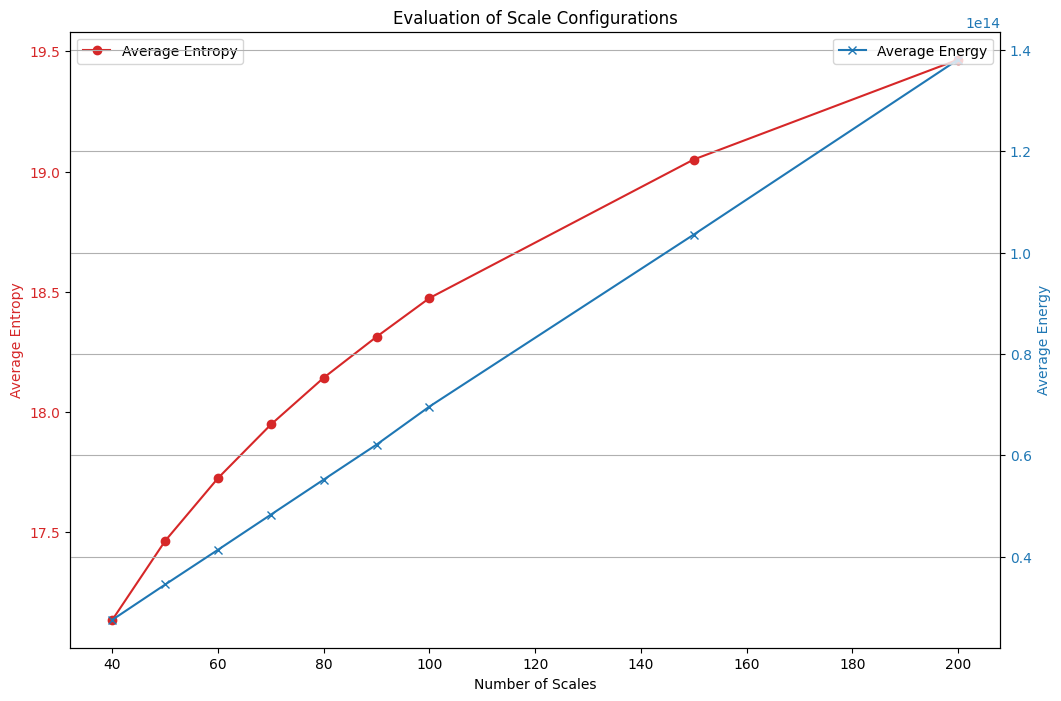

In [6]:
import matplotlib.pyplot as plt
# Calculate scale_counts from scale_options
scale_counts = [len(scales) for scales in scale_options]
def plot_scale_evaluations(scale_counts, average_entropies, average_energies):
    """
    Plot entropy and energy evaluations for different scale configurations.
    """
    fig, ax1 = plt.subplots(figsize=(12, 8))

    # Plot average entropy
    color = 'tab:red'
    ax1.set_xlabel('Number of Scales')
    ax1.set_ylabel('Average Entropy', color=color)
    ax1.plot(scale_counts, average_entropies, color=color, marker='o', label='Average Entropy')
    ax1.tick_params(axis='y', labelcolor=color)
    ax1.legend(loc='upper left')

    # Create a twin axis to plot average energy
    ax2 = ax1.twinx()
    color = 'tab:blue'
    ax2.set_ylabel('Average Energy', color=color)
    ax2.plot(scale_counts, average_energies, color=color, marker='x', label='Average Energy')
    ax2.tick_params(axis='y', labelcolor=color)
    ax2.legend(loc='upper right')

    plt.title('Evaluation of Scale Configurations')
    plt.grid(True)
    plt.show()

# Assuming `average_entropies` and `average_energies` are obtained as follows:
average_entropies = [np.mean(entropies) for entropies in scale_entropies.values()]
average_energies = [np.mean([np.sum(distribution) for distribution in energies]) for energies in scale_energy_distributions.values()]

plot_scale_evaluations(scale_counts, average_entropies, average_energies)

In [7]:
# 计算信息熵增益率
entropy_gain_ratios = []
for i in range(1, len(average_entropies)):
    scale_increase = scale_counts[i] - scale_counts[i-1]
    entropy_gain = average_entropies[i] - average_entropies[i-1]
    if scale_increase != 0:  # 避免除以零
        gain_ratio = entropy_gain / scale_increase
    else:
        gain_ratio = 0
    entropy_gain_ratios.append((gain_ratio, tuple(scale_counts)))

import matplotlib.pyplot as plt
def plot_entropy_vs_scales(average_entropies, scale_counts, entropies_std, entropy_gain_ratios):
    scale_labels = ['{} scales'.format(count) for count in scale_counts]
    normalized_entropies = [entropy / count for entropy, count in zip(average_entropies, scale_counts)]
    cv_entropies = [std / mean if mean != 0 else 0 for std, mean in zip(entropies_std, average_entropies)]
    gains, _ = zip(*entropy_gain_ratios)  # 分离增益率和对应的尺度配置

    fig, ax1 = plt.subplots(figsize=(10, 8))

    ax1.set_xlabel('Number of Scales')
    ax1.set_ylabel('Normalized Average Entropy', color='tab:red')
    ax1.bar(range(len(normalized_entropies)), normalized_entropies, color='tab:red', label='Normalized Entropy')
    ax1.tick_params(axis='y', labelcolor='tab:red')
    ax1.legend(loc='upper left')

    ax2 = ax1.twinx()
    ax2.set_ylabel('Coefficient of Variation', color='tab:blue')
    ax2.plot(range(len(cv_entropies)), cv_entropies, color='tab:blue', marker='o', label='CV of Entropy')
    ax2.tick_params(axis='y', labelcolor='tab:blue')
    ax2.legend(loc='upper right')

    ax3 = ax1.twinx()
    ax3.spines['right'].set_position(('outward', 60))  # 将第三个轴向右移动一些，以避免重叠
    ax3.set_ylabel('Entropy Gain Ratio', color='tab:green')
    ax3.plot(range(len(gains)), gains, color='tab:green', marker='x', label='Entropy Gain Ratio')
    ax3.tick_params(axis='y', labelcolor='tab:green')
    ax3.legend(loc='upper center')

    plt.xticks(range(len(scale_counts)), scale_labels)
    plt.title('Evaluation of Different Scale Ranges')
    plt.show()

# 调用可视化函数的示例（确保你已经有这些数据）
# plot_entropy_vs_scales(average_entropies, scale_counts, entropies_std, entropy_gain_ratios)
plot_entropy_vs_scales(average_entropies, scale_counts, entropies_std, entropy_gain_ratios)

NameError: name 'entropies_std' is not defined

In [ ]:
print("Scale counts:", len(scale_counts))
print("Average entropies:", len(average_entropies))
print("Entropies STD:", len(entropies_std))
print("Entropy gain ratios:", len(entropy_gain_ratios))

def plot_average_energy_by_scale_counts(scale_counts, average_energy_distributions):
    """
    绘制不同尺度配置下的平均能量。
    
    Args:
    scale_counts (list): 尺度计数列表，表示每个尺度配置包含的尺度数量。
    average_energy_distributions (list of lists): 每个尺度配置下的平均能量分布列表。
    """
    average_energies = [np.sum(dist) for dist in average_energy_distributions]  # 计算每个分布的总能量
    
    plt.figure(figsize=(12, 8))
    plt.bar(scale_counts, average_energies, color='teal')
    plt.title('Total Average Energy by Scale Count')
    plt.xlabel('Number of Scales')
    plt.ylabel('Total Average Energy')
    plt.grid(True)
    plt.show()
# 假设以下变量已根据上述batch_process函数的输出正确赋值
scale_counts = [len(scales) for scales in scale_options]

# 调用可视化函数
plot_average_energy_by_scale_counts(scale_counts, average_energy_distributions)

In [ ]:
# 计算信息熵增益率
entropy_gain_ratios = []
for i in range(1, len(average_entropies)):
    scale_increase = scale_counts[i] - scale_counts[i-1]
    entropy_gain = average_entropies[i] - average_entropies[i-1]
    if scale_increase != 0:  # 避免除以零
        gain_ratio = entropy_gain / scale_increase
    else:
        gain_ratio = 0
    entropy_gain_ratios.append((gain_ratio, tuple(scale_counts)))
# 寻找信息熵增益的转折点
def find_elbow_point(gain_ratios):
    # 可以使用肘部方法或其他曲线分析方法
    gains = [gr[0] for gr in gain_ratios]
    deltas = np.diff(gains)  # 计算增益的一阶差分
    elbow_index = np.argmin(deltas) + 1  # 寻找增益减少最多的点
    return elbow_index

elbow_index = find_elbow_point(entropy_gain_ratios)
optimal_num_scales = scale_counts[elbow_index]
print("Optimal number of scales based on elbow method:", optimal_num_scales)

In [ ]:

len(best_scales)
scale_counts
entropies_std
average_entropies
max(average_entropies)

In [ ]:
def plot_entropy_vs_scales(average_entropies, scale_counts, entropies_std):
    scale_labels = ['{} scales'.format(count) for count in scale_counts]
    normalized_entropies = [entropy / count for entropy, count in zip(average_entropies, scale_counts)]
    cv_entropies = [std / mean if mean != 0 else 0 for std, mean in zip(entropies_std, average_entropies)]

    fig, ax1 = plt.subplots(figsize=(10, 6))

    ax1.set_xlabel('Number of Scales')
    ax1.set_ylabel('Normalized Average Entropy', color='tab:red')
    ax1.bar(range(len(normalized_entropies)), normalized_entropies, color='tab:red', label='Normalized Entropy')
    ax1.tick_params(axis='y', labelcolor='tab:red')
    ax1.legend(loc='upper left')

    ax2 = ax1.twinx()
    ax2.set_ylabel('Coefficient of Variation', color='tab:blue')
    ax2.plot(range(len(cv_entropies)), cv_entropies, color='tab:blue', marker='o', label='CV of Entropy')
    ax2.tick_params(axis='y', labelcolor='tab:blue')
    ax2.legend(loc='upper right')

    plt.xticks(range(len(scale_counts)), scale_labels)
    plt.title('Evaluation of Different Scale Ranges')
    plt.show()

# 可视化信息熵与尺度的关系
plot_entropy_vs_scales(average_entropies, scale_counts, entropies_std)